In [13]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#create data
x_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8]) #decoding
y_soc = np.array([0,0,1,0,1,0,0,0,0,1.9]) #freezing

x_mockSFC = np.array([56.0,51.1,63.4,60.1,64.35, 58.4,  60.3, 55.9,  58.4, 52.7]) #decoding
y_mockSFC = np.array([0,0,0,0,1.3,1,0,0,0,1.4]) #freezing

x = np.subtract(x_mockSFC, x_soc)
y = np.subtract(y_mockSFC, y_soc)
flag = ['n' for i in range(len(x))]
#y = np.absolute(y)

print(x)
print(y)

print(np.corrcoef(x,y))
print(np.mean(y))

[ 2.7  -9.1   0.2  -2.   -4.25  2.3   2.5  -8.2   1.3  -3.1 ]
[ 0.   0.  -1.   0.   0.3  1.   0.   0.   0.  -0.5]
[[1.         0.10113031]
 [0.10113031 1.        ]]
-0.019999999999999997


In [57]:
x2_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8]) #decoding
y2_soc = np.array([1,2.7,0,0,1,0,0,0,1,0]) #freezing


x2_mockExt = np.array([55.3,60.4,64.7,57.4,65.6, 60.1, 59.8, 65.1,  56.4, 52.7]) #decoding
y2_mockExt = np.array([0,1,1,0,0,1,0,0,1.9,1]) #freezing


x2 = np.subtract(x2_mockExt, x2_soc)
y2 = np.subtract(y2_mockExt, y2_soc)
flag_2 = ['y' for i in range(len(x2))]
#y = np.absolute(y)

print(x2)
print(y2)
print('mean:')
print(np.mean(x2))
print(np.mean(y2))

print('Pearson\'s correlation:')
print(np.corrcoef(x2,y2))

[ 2.   0.2  1.5 -4.7 -3.   4.   2.   1.  -0.7 -3.1]
[-1.  -1.7  1.   0.  -1.   1.   0.   0.   0.9  1. ]
mean:
-0.08000000000000043
0.019999999999999973
Pearson's correlation:
[[1.         0.10028081]
 [0.10028081 1.        ]]


In [58]:
x_df = list(x)
x_df.extend(x2)
y_df = list(y)
y_df.extend(y2)
flag.extend(flag_2)

dataframe = pd.DataFrame(list(zip(x_df, y_df, flag)),columns=['x','y','r3r4'])

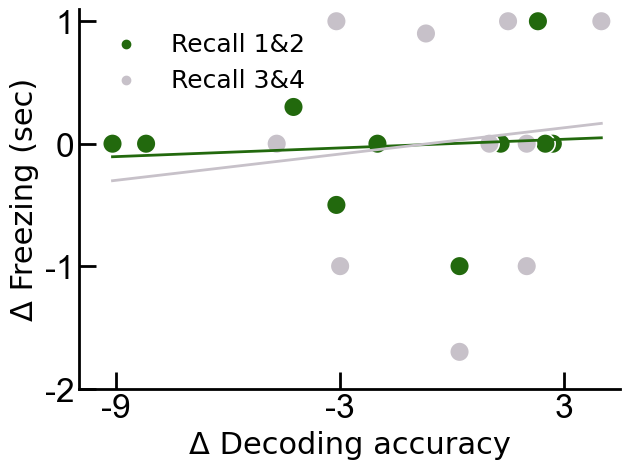

In [65]:
colors = ["#22690d","#c7c1c9"]

fig, ax = plt.subplots()  # create figure and axes

# plot on ax (Axes) object
sns.scatterplot(data=dataframe, x='x', y='y',hue='r3r4',palette=colors,s=200)

#mfc='none'
#obtain m (slope) and b(intercept) of linear regression line
m, b = np.polyfit(x, y, 1)
m2, b2 = np.polyfit(x2,y2,1)

#add linear regression line to scatterplot 
#ax.plot(x, m*x+b, color='#144e96')
l_reg_line = np.array([min(x.min(),x2.min()),max(x.max(),x2.max())])
ax.plot(l_reg_line, m*l_reg_line+b, color=colors[0], linewidth=2)
ax.plot(l_reg_line, m2*l_reg_line+b2, color=colors[1], linewidth=2)

ax.set_ylim([-2,1.1])
ax.set_yticks([-2,-1,0,1], fontname='Arial')
ax.set_yticklabels(['-2','-1','0','1'],fontname='Arial')

ax.set_xlim([-10,4.5])
ax.set_xticks([-9,-3,3], fontname='Arial')
ax.set_xticklabels(['-9','-3','3'],fontname='Arial')

sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.set_xlabel('Δ Decoding accuracy', fontsize=22)
ax.set_ylabel('Δ Freezing (sec)', fontsize=22)

#ax.tick_params(axis='both', which='major', )
ax.tick_params(axis='both', which='major', direction='in',length=12, labelsize=24, width=2)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles,['Recall 1&2', 'Recall 3&4'], fontsize = 18, frameon=False, loc='upper left')
#ax.get_legend().remove()


plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig5_FreezingControls.jpg",dpi=500)
plt.savefig('Fig5_FreezingControls.eps', format='eps')
